# Progetto Digital Forensic
## Campagnaro Matteo Matricola: 2155351

### Dataset:

### Dataset Info:
The data consists of the normal/anomalous operating sounds of seven types of real/toy machines:


1.   Fan
2.   Gearbox
3.   Pump
4.   Slide Rail
5.   Valve

Each sond is then divided in three section and each section is a complete set of training and test data.

Each section is compose of a training set of 1000 normal sample and a test set of 100 normal sample and 100 anomaly sample.
## Task:

Train a model that's able to distinguish the anomly sound from the normal one.


# Structure of the project


*   Estrazione delle feature using the librosa framework and some bibliography found online
*   Definition of the autoencoder and training of the model
*   



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Unzip the training and test set


In [ ]:
!7z x drive/MyDrive/dataset/source_test.zip
!7z x drive/MyDrive/dataset/train.zip


7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,2 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan         1 file, 155085393 bytes (148 MiB)

Extracting archive: drive/MyDrive/dataset/source_test.zip
--
Path = drive/MyDrive/dataset/source_test.zip
Type = zip
Physical Size = 155085393

  0%      0% 12 - source_test/section_01_source_test_normal_0000.wav                                                              1% 20 - source_test/section_01_source_test_normal_0028.wav                                                              4% 52 - source_test/section_00_source_test_anomaly_0065.

# Import libraries
## librosa
To sample the features of the sound files
## numpy
For utility
## sklearn, matplot lib
To analyze the reslt of the model
## tensorflow
To train the autoencoder used for recognition

In [ ]:
import librosa
import numpy as np
import os
import sys
import scipy.stats
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# Understanding vectors size
- The first step is the mel_spectrogram which use as a base the DFT (Discrete Fourier Transform) of the signal, in particular the DFT is a matrix of lenght (audio lenght)/hop_length and as the height the frequency resolution = n_fft -> DFT.shape = (n_fft, time_lenght), with the std. parameter and the audio file in the dataset: DFT.shape(1024,313)

- Then the shape of the mel_spectrogram is (n_mels, time_lenght), with the std. parameter and the audio file in the dataset: mel_spectrogram.shape(64,313)

- At the end a sliding window approach is applied to the mel_spectrogram. So at each iteration i'm selecting all the mels_filter and the time interval of n_vectors (309 with std. param -> to get 5 frames).

- As result, a rows of the vector will contain the filter of the first (n_frames)

In [ ]:
def file_to_features(file_name,
                    n_mels=64,
                    n_frames=5,
                    n_fft=1024,
                    hop_length=512,
                    power=2.0):
    # generate melspectrogram using librosa
    y, sr = librosa.load(file_name, sr=None, mono=True)#none
    mel_spectrogram = librosa.feature.melspectrogram(y=y,
                                                     sr=sr,
                                                     n_fft=n_fft,
                                                     hop_length=hop_length,
                                                     n_mels=n_mels,
                                                     power=power)
    # convert melspectrogram to log mel energies
    log_mel_spectrogram = 20.0 / power * np.log10(np.maximum(mel_spectrogram, sys.float_info.epsilon))


    n_vectors = len(log_mel_spectrogram[0, :]) - n_frames + 1
    #n_mels * n_frames = concatenation of the first #(n_frames) filter: n_mels
    vectors = np.zeros((n_vectors, n_mels * n_frames))
    for t in range(n_frames):
      # now the vector rows rappresent time, the columns the sample
        vectors[:, n_mels * t : n_mels * (t + 1)] = log_mel_spectrogram[:, t : t + n_vectors].T
    return vectors

# The n_hop frames is used to downsample the data
since the file_to_vector add redundancy using the sliding window method, this parameter will reduce the ammount of data and their dependency

In [ ]:
def file_list_to_data(file_list,
                      n_mels=64,#64
                      n_frames=5,#5
                      n_hop_frames=1,#1
                      n_fft=1024,
                      hop_length=512,#512
                      power=2.0):
    # consider the label
    y_true = np.zeros(len(file_list), dtype=int)
    for idx in range(len(file_list)):
        if "anomaly" in file_list[idx]:
            y_true[idx] = 1
        #print(f"{file_list[idx]} --> {y_true[idx]}")
        vectors = file_to_features(file_list[idx],
                                                n_mels=n_mels,
                                                n_frames=n_frames,
                                                n_fft=n_fft,
                                                hop_length=hop_length,
                                                power=power)
        vectors = vectors[: : n_hop_frames, :]
        if idx == 0:
            data = np.zeros((len(file_list) * vectors.shape[0], n_mels * n_frames), float)
        data[vectors.shape[0] * idx : vectors.shape[0] * (idx + 1), :] = vectors

    return data, y_true

In [ ]:
def get_files_list(directory = "source_test", section = "section_00"):
  return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.wav') if section in f]

In [ ]:
# Directory dei file audio
def get_data(directory = "source_test", section = "section_00"):
  files = get_files_list(directory, section)
  data, y_true = file_list_to_data(files)
  return data, y_true, len(files)

In [ ]:
def separate_data(data, y_true, n_vectors_ea_file):
    # Calculate file length and ensure it's a perfect integer
    file_len = data.shape[0] / n_vectors_ea_file
    if file_len.is_integer():
        file_len = int(file_len)
    else:
        raise ValueError("The file len isn't a perfect integer")

    # Initialize empty arrays for normal and anomaly data with the same shape as data
    n_anomalies = y_true.tolist().count(1)
    normal_data = np.zeros(((len(y_true.tolist()) - n_anomalies)*n_vectors_ea_file, data.shape[1]))
    anomaly_data = np.zeros((n_anomalies*n_vectors_ea_file, data.shape[1]))

    start_idx = 0
    normal_idx = 0
    anomaly_idx = 0
    for file_idx in range(file_len):
        current_slice = data[start_idx : start_idx + n_vectors_ea_file, :]
        if y_true[file_idx] == 0:
            normal_data[normal_idx : normal_idx + n_vectors_ea_file, :] = current_slice
            normal_idx += n_vectors_ea_file
        else:
            anomaly_data[anomaly_idx : anomaly_idx + n_vectors_ea_file, :] = current_slice
            anomaly_idx += n_vectors_ea_file
        start_idx += n_vectors_ea_file
    return normal_data, anomaly_data


# Data visualization

In [ ]:
def mel_plot(file_name):
    y, sr = librosa.load(file_name, sr=None, mono=True)
    mel_spectrogram = librosa.feature.melspectrogram(y=y,
                                                     sr=sr,
                                                     n_fft=1024,
                                                     hop_length=512,
                                                     n_mels=64,
                                                     power=2)
    fig, ax = plt.subplots()
    S_dB = librosa.power_to_db(mel_spectrogram, ref=np.max)
    img = librosa.display.specshow(S_dB, x_axis='time',
                             y_axis='mel', sr=sr,
                             fmax=8000, ax=ax)
    fig.colorbar(img, ax=ax, format='%+2.0f dB')
    ax.set(title=f"Mel-frequency spectrogram {file_name}")

In [ ]:
def dft_plot(file_name):
    y, sr = librosa.load(file_name, sr=None, mono=True)
    dft = np.fft.fft(y)
    # Get the magnitude spectrum
    magnitude_spectrum = np.abs(dft)
    # Get the frequency bins
    frequencies = np.fft.fftfreq(len(dft), 1/sr)
    plt.figure(figsize=(10, 4))
    plt.plot(frequencies, magnitude_spectrum)
    plt.title(f"Magnitude Spectrum of {file_name}")
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.xlim(0, sr/2)  # Limit to positive frequencies
    plt.grid(True)
    plt.show()

# Getting the training data
## in particular from the train folder

In [ ]:
data, y_true, n_files = get_data("train")

# Separate data
## even if the dataset grant that the training set is compose of only normal data

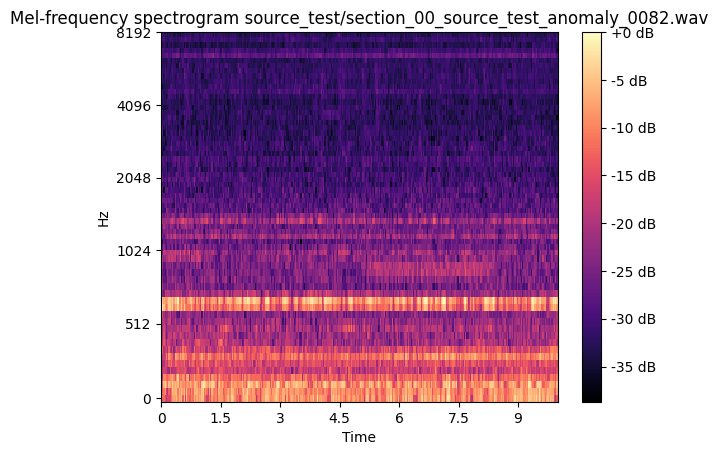

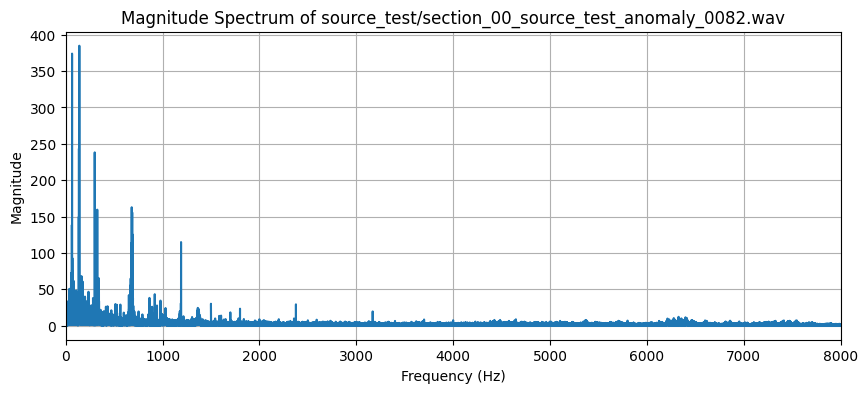

#files 1003
data (309927, 320)
# vector for each file 309
---------------
normal data shape (309927, 320)
#of normal file 1003


In [ ]:
mel_plot(get_files_list()[2])
dft_plot(get_files_list()[2])
n_vectors_ea_file = int(data.shape[0] / n_files)
normal_data, anomaly_data = separate_data(data = data, y_true = y_true, n_vectors_ea_file = n_vectors_ea_file)
normal_len = int(normal_data.shape[0] / n_vectors_ea_file)
anomaly_len = int(anomaly_data.shape[0] / n_vectors_ea_file)
print(f"#files {n_files}")
print(f"data {data.shape}")
print(f"# vector for each file {n_vectors_ea_file}")
print("---------------")
print(f"normal data shape {normal_data.shape}")
print(f"#of normal file {normal_len}")

In [ ]:
def normalize_matrix(matrix):
  max = np.max(matrix)
  min = np.min(matrix)
  new_matrix = (matrix - min) / (max)

  return new_matrix

def to_matrix(X, n_files):
  k = X.shape[0] // n_files
  print(f"matrix X shape {X.shape}")
  print(f"matrix n_file {n_files}")
  print(f"matrix k {k}")
  matrix = np.zeros((n_files, k, X.shape[1]))
  for idx in range(n_files):
    matrix[idx:] = X[idx * k : (idx + 1) * k:]
  return normalize_matrix(matrix)

In [ ]:
from tensorflow.keras import layers
class Autoencoder(Model):
    def __init__(self, shape):
        super(Autoencoder, self).__init__()
        self.shape = shape

        self.output_shape_prod = np.prod(shape)

        self.encoder = tf.keras.Sequential([
          layers.Flatten(),
          layers.Dense(64, activation="relu"),
          layers.Dense(64, activation="relu"),
          layers.Dense(32, activation="relu"),
          layers.Dense(16, activation="relu"),
          layers.Dense(8, activation="relu")])

        self.decoder = tf.keras.Sequential([
          layers.Dense(16, activation="relu"),
          layers.Dense(32, activation="relu"),
          layers.Dense(64, activation="relu"),
          layers.Dense(64, activation="relu"),
          layers.Dense(self.output_shape_prod, activation=None),
          layers.Reshape(shape)])

    def call(self, x):
        print(self.shape)
        encoded = self.encoder(x)
        print(f"Encoded shape: {encoded.shape}")
        decoded = self.decoder(encoded)
        return decoded

In [ ]:
input_dim = normal_data.shape[1]
print(input_dim)
bottleneck_units = 8
hidden_units = 128
epochs = 60
batch_size = 512
learning_rate = 0.001

In [ ]:
normal_matrix = to_matrix(normal_data, n_files)
print(normal_matrix[1].shape[0:])
autoencoder = Autoencoder(normal_matrix[1].shape[0:])
autoencoder.compile(optimizer='adam', loss='mean_squared_error')
autoencoder.summary()
history = autoencoder.fit(normal_matrix,
                              normal_matrix,
                              epochs=epochs,
                              shuffle=True,
                              batch_size = 56,
                              validation_split=0.1)

matrix X shape (309927, 320)
matrix n_file 1003
matrix k 309
(309, 320)


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
(309, 320)
Encoded shape: (None, 8)
(309, 320)
Encoded shape: (None, 8)
(309, 320)
Encoded shape: (None, 8)
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - loss: 3.3318(309, 320)
Encoded shape: (None, 8)
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 285ms/step - loss: 3.2380 - val_loss: 0.1958
Epoch 2/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 337ms/step - loss: 0.1900 - val_loss: 0.1396
Epoch 3/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 224ms/step - loss: 0.1281 - val_loss: 0.1261
Epoch 4/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 253ms/step - loss: 0.1183 - val_loss: 0.1227
Epoch 5/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 336ms/step - loss: 0.1205 - val_loss: 0.1224
Epoch 6/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 248ms/step - loss: 0.1225 - val_loss: 0.1248
Epoch 7/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 343ms/step - loss: 0.1181 - val_loss: 0.1225
Epoch 8/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 297ms/step - loss: 0.1151 - val_loss: 0.1235
Epoch 9/60
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 316ms/step - loss: 0.1169 - val_loss: 0.1216
Epoch 10/60
17/17 ━━━━━━━━━

In [ ]:
def predict_matrix(file_len, data, model, n_vector_ea_file):
  y_pred = []
  start_idx = 0
  data_matrix = to_matrix(data, file_len)
  print(data_matrix[1].shape)
  for file_idx in range(file_len):
    # Ensure each file's data has a batch dimension
        file_data = np.expand_dims(data_matrix[file_idx], axis=0)  # Add batch dimension
        # Predict using the model
        reconstructed = model.predict(file_data, verbose=0)
        # Compute mean squared error
        mse = np.mean(np.square(data_matrix[file_idx] - reconstructed[0]))  # Remove batch dim
        y_pred.append(mse)
  return y_pred
y_normal_pred  = predict_matrix(normal_len, normal_data, autoencoder, n_vectors_ea_file)

matrix X shape (309927, 320)
matrix n_file 1003
matrix k 309
(309, 320)
(309, 320)
Encoded shape: (1, 8)


# Predict the label, the threshold
## gamma distribution
   * **`shape_hat`**: The estimated shape parameter (α) of the Gamma distribution.

   * **`loc_hat`**: The estimated location parameter (β) of the Gamma distribution.

   * **`scale_hat`**: The estimated scale parameter of the Gamma distribution.

   * The function **finds the threshold** such that the probability of a random variable from the Gamma distribution being less than or equal to the threshold is equal to `q`.
   
## Label legend
0 - normal

1 - anomaly

In [ ]:
def get_threshold(y,q = 0.70):
    shape_hat, loc_hat, scale_hat = scipy.stats.gamma.fit(y)
    return scipy.stats.gamma.ppf(q=q, a=shape_hat, loc=loc_hat, scale=scale_hat)

def predict_label(y_pred,threshold):
    y_label = []
    for y in y_pred:
      if y > threshold:
        y_label.append(1)
      else:
        y_label.append(0)
    return y_label

def measure(y_true, y_pred):
    # Initialize counts
    TP = TN = FP = FN = 0

    # Loop through true and predicted values to calculate counts
    for true, pred in zip(y_true, y_pred):
        if true == 1 and pred == 1:
            TP += 1  # True Positive
        elif true == 0 and pred == 0:
            TN += 1  # True Negative
        elif true == 1 and pred == 0:
            FN += 1  # False Negative
        elif true == 0 and pred == 1:
            FP += 1  # False Positive
    return TP, TN, FP, FN

In [ ]:
decision_threshold = get_threshold(y_normal_pred)
data_label = predict_label(y_normal_pred, decision_threshold)
print(measure(y_true,data_label))

(0, 638, 365, 0)


In [ ]:
from sklearn.metrics import roc_curve, auc
def visualize_result(y_true, y_pred):
    # Calculate the metrics
    print(measure(y_true_test,y_pred))
    TP, TN, FP, FN = measure(y_true_test,y_pred)
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1_score = 2 * (precision * recall) / (precision + recall)

    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-Score: {f1_score:.2f}")

    # Confusion Matrix
    cm = np.array([[TN, FP], [FN, TP]])
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.matshow(cm, cmap='Blues', alpha=0.7)
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, value, ha='center', va='center', color='red', fontsize=14)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Negative', 'Positive'])
    ax.set_yticklabels(['Negative', 'Positive'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    plt.title('Confusion Matrix', fontsize=16)
    plt.show()

    # ROC Curve (For demonstration, use random values for fpr, tpr)
    # In practice, you would use `roc_curve` from your model's probabilities.
    fpr, tpr, thresholds = roc_curve(y_true, y_pred)
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=16)
    plt.legend(loc='lower right')
    plt.show()

# getting the testing data to test



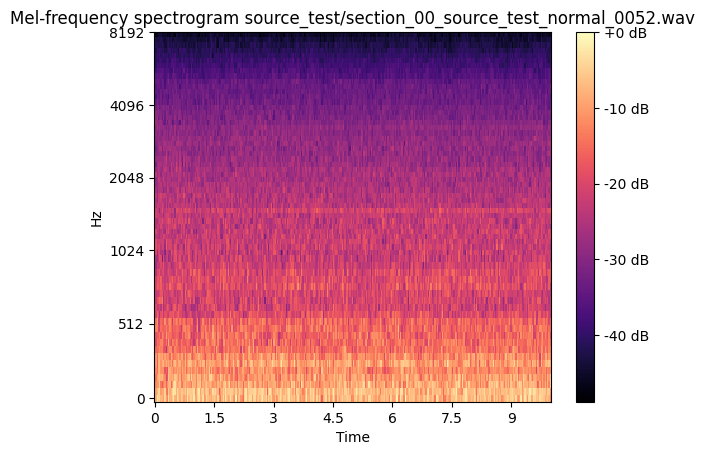

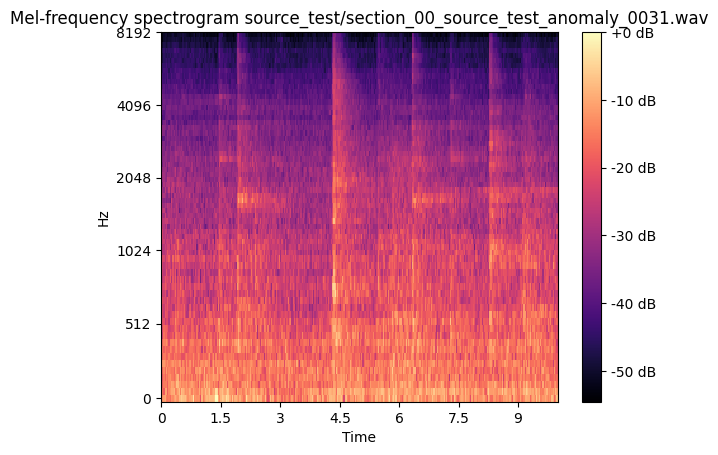

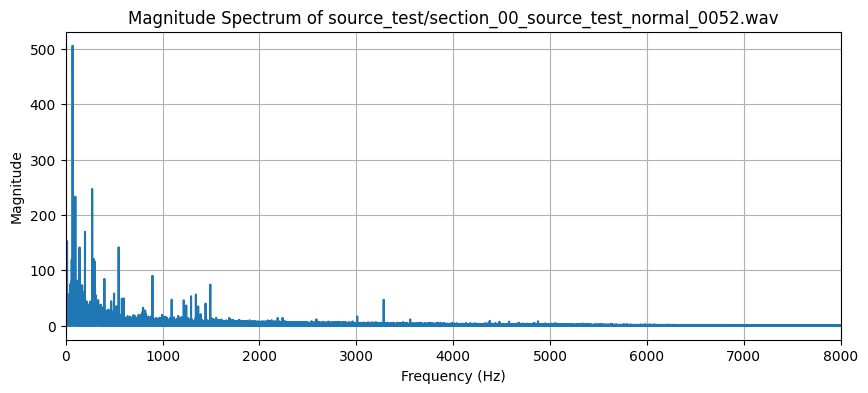

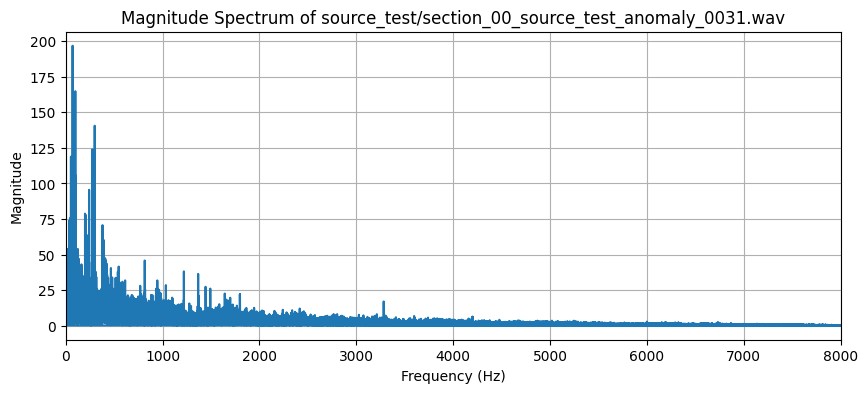

In [ ]:
test_directory = "source_test"
data_test, y_true_test, n_files_test = get_data(directory = test_directory)
files = get_files_list(directory = test_directory)
anomalie_file = files[np.where(y_true_test == 1)[0][0]]
normal_file = files[np.where(y_true_test == 0)[0][0]]
mel_plot(normal_file)
mel_plot(anomalie_file)
dft_plot(normal_file)
dft_plot(anomalie_file)

In [ ]:
print(n_files_test)
data_pred_test = predict_matrix(n_files_test, data_test, autoencoder, n_vectors_ea_file)
data_label_test = predict_label(data_pred_test, decision_threshold)

200
matrix X shape (61800, 320)
matrix n_file 200
matrix k 309
(309, 320)


(46, 59, 41, 54)
Accuracy: 0.53
Precision: 0.53
Recall: 0.46
F1-Score: 0.49


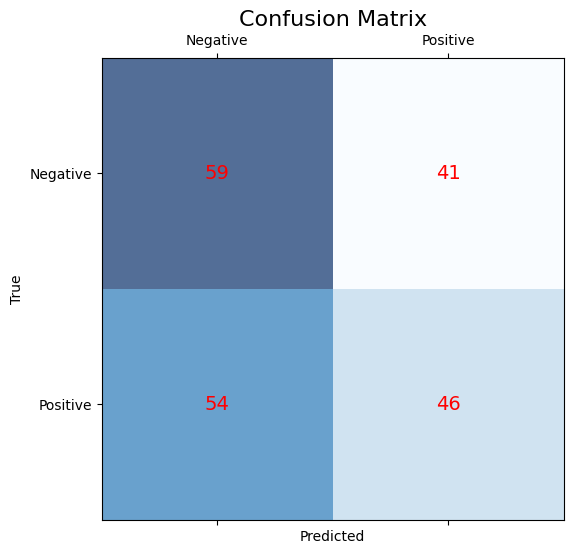

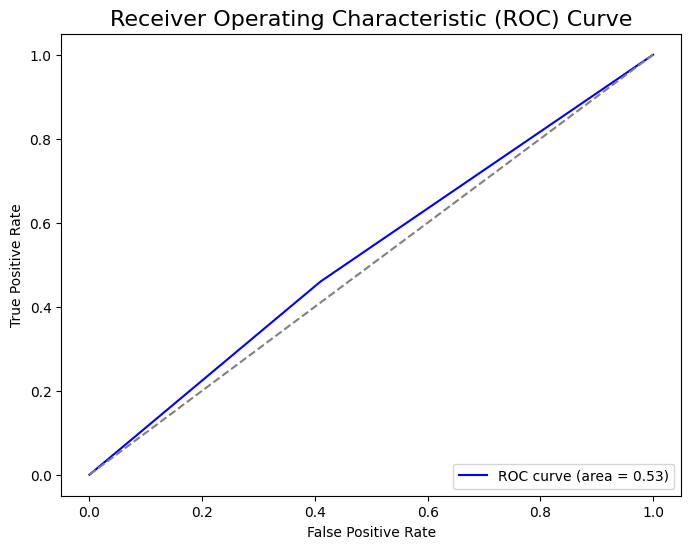

In [ ]:
visualize_result(y_true_test,data_label_test)

# Test with ML on latent space

In [ ]:
from sklearn.preprocessing import StandardScaler
def fit(X):
  scaler = StandardScaler()
  scaler.fit(X)
  return scaler

def transform(X, scaler):
  return scaler.transform(X)


def evaluate_series(data_label, n_files):
  # Length of the array
    n = len(data_label)
    k = int(n / n_files)
    # Ensure n is divisible by k
    if n % k != 0:
        raise ValueError("Array length n must be divisible by k")

    # New array to store the result
    result = np.zeros(n_files, dtype = int)

    # Iterate through each frame
    for i in range(n_files):
        # Get the current frame
        frame = data_label[i * k: (i + 1) * k]

        # Count zeros and ones in the frame
        zeros = np.sum(frame == 0)
        ones = k - zeros  # Since all elements are 0 or 1

        # If there are more zeros than ones, mark as 1 in the result array
        if zeros > ones:
            result[i] = 1
        else:
            result[i] = 0
    print(result.shape)
    return result


In [ ]:
from sklearn.svm import OneClassSVM
from tensorflow.keras.models import Model

# Assuming you have trained your autoencoder (autoencoder) and have data (x_train, x_test)

# 1. Extract Bottleneck Features
#bottleneck_model = Model(inputs=autoencoder.input, outputs=autoencoder.get_layer('bottleneck_layer').output)  # Replace 'bottleneck_layer_name' with the actual name of your bottleneck layer
#bottleneck_train_features = bottleneck_model.predict(normal_data)  # Extract features from nominal training data only
#bottleneck_test_features = bottleneck_model.predict(data_test)
bottleneck_train_features = autoencoder.encoder(to_matrix(normal_data, n_files))
bottleneck_test_features = autoencoder.encoder(to_matrix(data_test, n_files_test))
print(bottleneck_train_features.shape)
# 2. Train One-Class SVM
#ocsvm = OneClassSVM(nu=0.1, kernel='rbf', gamma='scale', verbose=1)  # Adjust hyperparameters as needed
#ocsvm.fit(bottleneck_train_features)

# 3. Predict Anomalies
#data_label_test = ocsvm.predict(bottleneck_test_features)

matrix X shape (309927, 320)
matrix n_file 1003
matrix k 309
matrix X shape (61800, 320)
matrix n_file 200
matrix k 309
(1003, 8)


In [ ]:
from sklearn.ensemble import IsolationForest
scaler = fit(bottleneck_train_features)
bottleneck_train_scaled = transform(bottleneck_train_features, scaler)
bottleneck_test_scaled = transform(bottleneck_test_features, scaler)
iso_forest = IsolationForest(n_estimators = 10, random_state=42, verbose=1)
iso_forest.fit(bottleneck_train_features)

# 3. Predict Anomalies
data_label_test = iso_forest.predict(bottleneck_test_features)

In [ ]:
ocsvm = OneClassSVM(nu=0.1, kernel='rbf', gamma='scale', verbose=1)  # Adjust hyperparameters as needed
ocsvm.fit(bottleneck_train_features)

# 3. Predict Anomalies
data_label_test = ocsvm.predict(bottleneck_test_features)

In [ ]:
print(data_label_test.shape)

(200,)


(1, 0, 1, 0)
(99, 1, 99, 1)
Accuracy: 0.50
Precision: 0.50
Recall: 0.99
F1-Score: 0.66


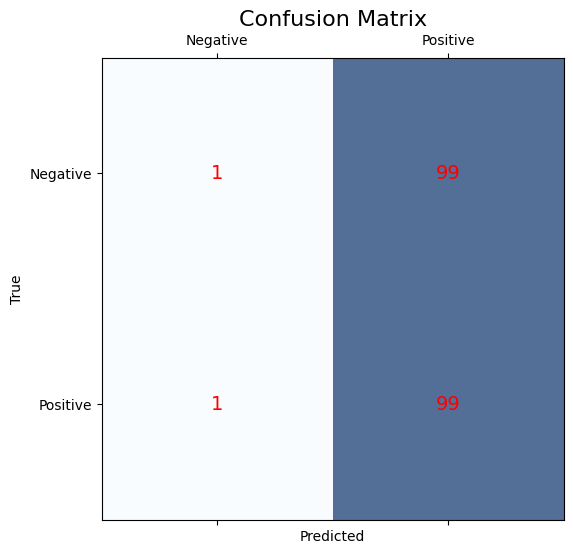

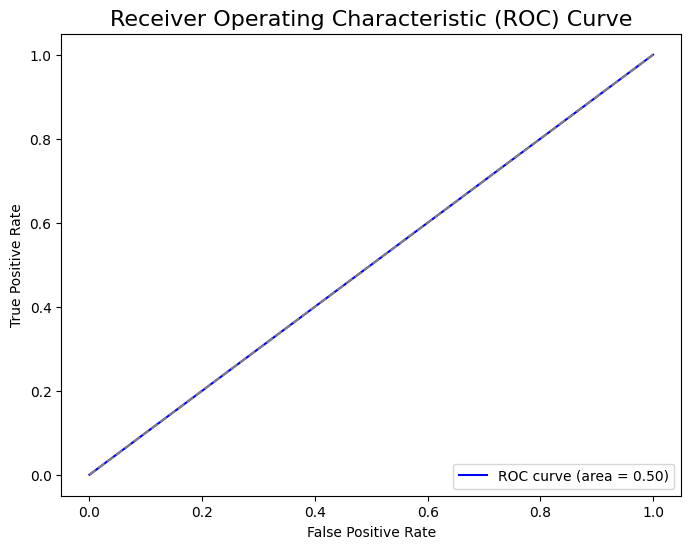

In [ ]:
data_label_test_adapt = np.where(data_label_test == 1, 0, 1)
#evaluated = evaluate_series(data_label_test_adapt,n_files_test)
print(measure(y_true_test, data_label_test))
visualize_result(y_true_test,data_label_test_adapt)